In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [18]:
yahoo = pd.read_csv('time_series_US_20031231-1800_20261011-1650.csv')

N = len(yahoo)
t = np.arange(1, N+1)

y = yahoo['yahoo']
X = np.zeros((N,N))

lmbda = np.logspace(0,6,7)

for i in range(1,N):
    X[:,i] = np.maximum((t - i),0)
X[:,0] = 1
sym.pprint(X)
yahoo.head()

[[  1.   0.   0. ...   0.   0.   0.] 
 [  1.   1.   0. ...   0.   0.   0.] 
 [  1.   2.   1. ...   0.   0.   0.] 
                 ...                 
 [  1. 271. 270. ...   1.   0.   0.] 
 [  1. 272. 271. ...   2.   1.   0.] 
 [  1. 273. 272. ...   3.   2.   1.]]


,Time,yahoo
0,2004-01-01,39
1,2004-02-01,39
2,2004-03-01,40
3,2004-04-01,41
4,2004-05-01,42


In [22]:
K = 5
idx = np.arange(N)

D = np.ones(N)
D[:2] = 0
D = np.diag(D)

cv_error = []
for lam in lmbda:
    fold_error = []
    for k in range(K):
        test  = (idx % K == k)
        train = ~test
        X_train, y_train = X[train], y[train]
        X_test,  y_test  = X[test],  y[test]

        A = X_train.T @ X_train + lam * D
        b = X_train.T @ y_train
        beta_hat = np.linalg.solve(A, b)

        pred = X_test @ beta_hat
        fold_error.append(np.mean((y_test - pred)**2))

    cv_error.append(np.mean(fold_error))   # one number per λ

best_lam = lmbda[np.argmin(cv_error)]
print(best_lam)

1.0


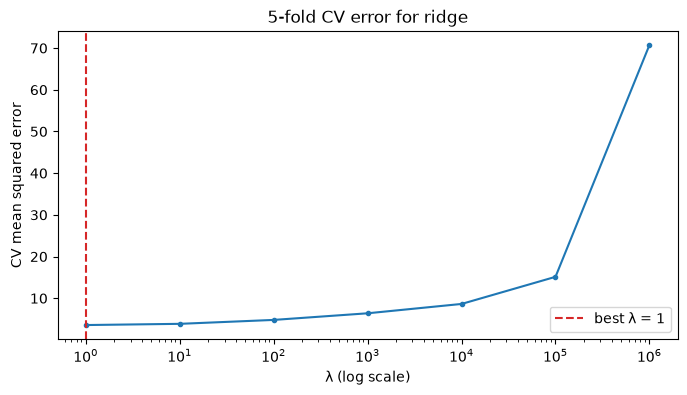

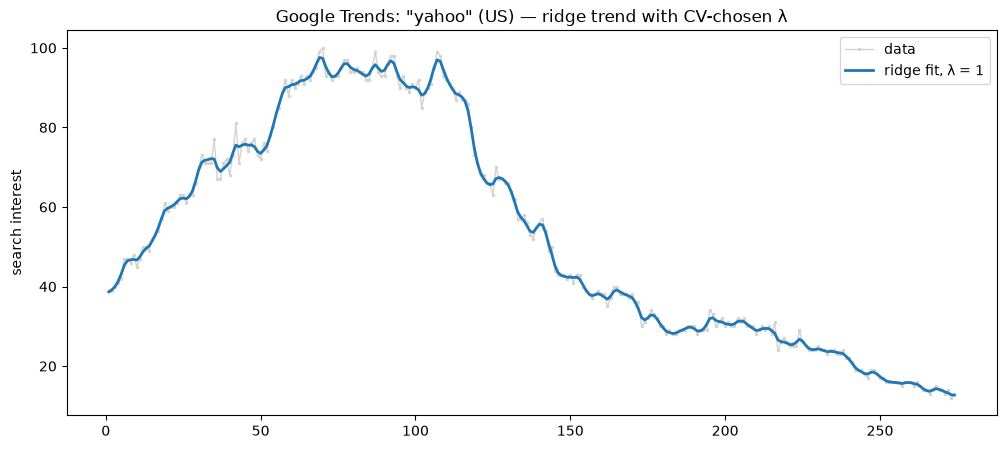

In [25]:

plt.figure(figsize=(8, 4))
plt.semilogx(lmbda, cv_error, marker='o', ms=3)
plt.axvline(best_lam, color='C3', ls='--', label=f'best λ = {best_lam:.3g}')
plt.xlabel('λ (log scale)'); plt.ylabel('CV mean squared error')
plt.title('5-fold CV error for ridge')
plt.legend(); plt.show()

A = X.T @ X + best_lam * D
beta_best = np.linalg.solve(A, X.T @ y)
mu_best = X @ beta_best

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, marker='.', ms=3, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge fit, λ = {best_lam:.3g}')
plt.ylabel('search interest'); plt.title('Google Trends: "yahoo" (US) — ridge trend with CV-chosen λ')
plt.legend()
plt.show()

The fitted trend function fits the data and is able capture the general trend. However we do see that the trend is not able to capture some of the jumps and peaks.